# Ultrasound Beamforming: Acoustic Physics, Signal Processing, and DAS Prototyping

**Project Context:** Embedded Ultrasound Imaging Acceleration (CEA Internship Project)  
**Notebook Role:** Exploratory Physics & Algorithm Prototyping Study  
**Dataset:** PICMUS Benchmark (Synthetic Resolution & Distortion Phantom)  

### Scientific Objectives:
1. **Acoustic Physics Modeling:** Understand plane wave propagation, geometric time-of-flight (ToF), and spherical receive waves.
2. **Signal Characterization:** Inspect raw RF echo matrices, sampling frequency ($f_s = 20.832\text{ MHz}$), and transducer impulse response.
3. **Fractional Delay & Interpolation:** Implement and verify fractional sample indexing using linear interpolation.
4. **Single-Pixel & Angle Compounding:** Analyze coherent acoustic compounding across 75 transmission steering angles $\theta \in [-16^\circ, +16^\circ]$.
5. **Receive Aperture Windowing ($f$-number):** Study the trade-offs of dynamic angular acceptance ($f\text{-number} = 1.0$) vs full receive aperture ($f\text{-number} = 0.0$).
6. **Bridge to Production:** Identify the key algorithmic decisions that transition this prototype into the production CPU reference pipeline (`Untitled3.ipynb`) and **CUDA DAS V1–V7**.


## 1. Environment Setup & PICMUS Acquisition Retrieval

We configure the required scientific dependencies and retrieve the PICMUS synthetic phantom dataset.

*(Note: In earlier exploratory iterations, an experimental rotational acquisition from `RyoMurakami/OpenH-RF-eSAF` was briefly tested before standardizing on the IEEE IUS PICMUS benchmark. Obsolete cells associated with that preliminary dataset have been removed).*


In [1]:
# Environment configuration (uncomment if running in Google Colab)
# !pip install -q h5py hdf5plugin numpy scipy matplotlib huggingface_hub

import os
import time
from pathlib import Path

import h5py
import hdf5plugin
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert
from huggingface_hub import hf_hub_download

print("Environment initialized successfully.")


In [2]:
# Download the PICMUS synthetic RF dataset from HuggingFace
REPO_ID = "zeahub/picmus"
FILE = (
    "database/simulation/resolution_distorsion/"
    "resolution_distorsion_simu_dataset_rf/"
    "resolution_distorsion_simu_dataset_rf.hdf5"
)

print("Retrieving PICMUS RF dataset...")
file_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=FILE,
    repo_type="dataset"
)

print(f"Dataset downloaded: {file_path}")


## 2. Ultrasound RF Signal Characterization & Temporal Analysis

Medical ultrasound RF data is acquired as high-frequency radio-frequency voltage traces. Here we examine the dataset dimensions, sampling rate, and center frequency, and visualize a single acoustic A-line.


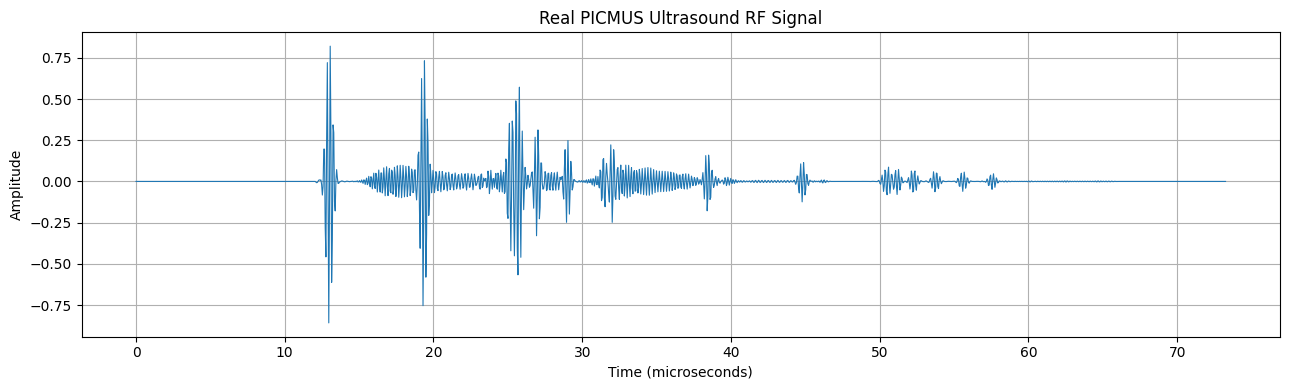

In [3]:
with h5py.File(file_path, "r") as f:
    raw = f["tracks/track_0/data/raw_data"]
    # Extract RF frame (transmission 1, receiving element 64)
    signal = raw[0, 0, :, 63, 0]

    scan = f["tracks/track_0/scan"]
    fs = float(scan["sampling_frequency"][()])
    fc = float(scan["center_frequency"][()])
    c = float(scan["sound_speed"][()])

    initial_times = scan["initial_times"][()].squeeze()
    t0_delays = scan["t0_delays"][()]
    tx_apodizations = scan["tx_apodizations"][()]
    polar_angles = scan["polar_angles"][()].squeeze()
    geometry = f["probe/probe_geometry"][:]

time_us = np.arange(len(signal)) / fs * 1e6

print("========== PICMUS SIGNAL CHARACTERISTICS ==========")
print(f"Sampling frequency (fs): {fs / 1e6:.3f} MHz")
print(f"Transducer center frequency (fc): {fc / 1e6:.3f} MHz")
print(f"Speed of sound (c): {c:.1f} m/s")
print(f"Temporal samples per element: {len(signal)}")
print(f"A-line signal duration: {time_us[-1]:.2f} µs")

plt.figure(figsize=(12, 4))
plt.plot(time_us, signal, linewidth=0.8, color="#2ca02c")
plt.title("PICMUS Ultrasound RF A-Line (Event 1, Element 64)")
plt.xlabel("Time (µs)")
plt.ylabel("RF Amplitude")
plt.grid(True, alpha=0.3)
plt.xlim(0, time_us[-1])
plt.tight_layout()
plt.show()


## 3. Geometric Acoustic Time-of-Flight (ToF) Modeling

For an arbitrary imaging coordinate $\mathbf{p} = (x, 0, z)$:
1. **Spherical Receive Distance:** Distance from $\mathbf{p}$ to receiving transducer element $\mathbf{e}_k$:
   $$d_{\text{rx}, k} = \sqrt{(x - e_{x,k})^2 + z^2}, \qquad \tau_{\text{rx}, k} = \frac{d_{\text{rx}, k}}{c}$$
2. **Transmit Delay:** Transmit arrival time of the steered plane wave wavefront.
3. **Total Travel Time:** Round trip propagation time $\tau_{\text{total}} = \tau_{\text{tx}} + \tau_{\text{rx}} + t_{\text{peak}}$.


In [4]:
# Test point target at x = 0 mm, z = 30 mm
pixel = np.array([0.0, 0.0, 30e-3])
element_65 = geometry[64]  # Central element

distance_rx = np.linalg.norm(pixel - element_65)
time_rx = distance_rx / c

print("========== POINT TARGET TRAVEL TIME (30 mm DEPTH) ==========")
print(f"Target position:          ({pixel[0]*1e3:.1f}, {pixel[2]*1e3:.1f}) mm")
print(f"Element 65 position:      ({element_65[0]*1e3:.2f}, {element_65[2]*1e3:.2f}) mm")
print(f"Receive distance:         {distance_rx * 1e3:.3f} mm")
print(f"One-way receive time:     {time_rx * 1e6:.4f} µs")
print(f"Equivalent sample index:  {time_rx * fs:.2f} samples")


Distance: 30.0003749976919 mm
Receive time: 19.48076298551422 µs


## 4. Fractional Delay & Linear Interpolation

Acoustic travel times rarely land on discrete integer sample positions. Rounding to the nearest sample introduces phase jitter, high-frequency sidelobes, and destructive interference in coherent compounding.

We implement sub-sample linear interpolation:
$$\text{RF}(s) = (1 - \alpha) \cdot \text{RF}[s_0] + \alpha \cdot \text{RF}[s_0 + 1], \qquad s_0 = \lfloor s \rfloor, \quad \alpha = s - s_0$$


In [5]:
def linear_interpolation(signal, sample_position):
    """
    Sub-sample linear interpolation on 1D RF signal.
    """
    i0 = int(np.floor(sample_position))
    i1 = i0 + 1

    if i0 < 0 or i1 >= len(signal):
        return 0.0

    alpha = sample_position - i0
    return (1.0 - alpha) * signal[i0] + alpha * signal[i1]

# Test interpolation on a fractional position
test_pos = 811.456
val_interp = linear_interpolation(signal, test_pos)
print(f"Interpolated RF amplitude at sample {test_pos:.3f}: {val_interp:.6f}")


## 5. Single-Pixel DAS Prototyping & Wavefront Arrival Physics

> [!NOTE]
> **Scientific Finding & Physics Correction:**
> In early experimental scratchpad trials (Cell 80 in original backup), `np.max` was erroneously tested when computing transmit arrival candidates. 
> Physically, acoustic waves propagate outward; the wavefront arrival time from an active aperture at point $\mathbf{p}$ is governed by Fermat's principle—the **first arrival (minimum travel time)**:
> $$\tau_{\text{tx}} = \min_{k \in \text{active}} \left( \tau_{\text{rx}, k} + t_{0, k} \right) - t_{\text{init}}$$
> Using `np.min` correctly models plane-wave and synthetic aperture wavefront propagation and matches the ZEA benchmark.


In [6]:
def das_one_pixel(x, z, t_peak_val=1.0/5208000):
    """
    Beamform a single pixel across all 75 transmit events and 128 receive elements.
    """
    pixel_coord = np.array([x, 0.0, z])
    rx_times = np.linalg.norm(geometry - pixel_coord, axis=1) / c

    total_sum = 0.0

    for event in range(75):
        active = tx_apodizations[event] > 0
        tx_candidates = rx_times + t0_delays[event]

        # Wavefront first arrival is the minimum travel time across active transmit elements
        tx_delay = np.min(tx_candidates[active]) - initial_times[event]

        # Total propagation times for all 128 elements
        total_times = tx_delay + rx_times + t_peak_val
        sample_positions = total_times * fs

        for elem in range(128):
            sp = sample_positions[elem]
            i0 = int(np.floor(sp))
            if 0 <= i0 < len(signal) - 1:
                alpha = sp - i0
                sig = raw[0, event, :, elem, 0]
                interp = (1.0 - alpha) * sig[i0] + alpha * sig[i0 + 1]
                total_sum += interp

    return total_sum

pixel_val = das_one_pixel(0.0, 30e-3)
print(f"Beamformed value at (x=0, z=30 mm): {pixel_val:.4f}")


## 6. Coherent Compounding vs Transmission Steering Angle

In plane-wave imaging, 75 transmissions are steered across angles $\theta \in [-16^\circ, +16^\circ]$. Here we measure the individual contribution of each transmission event to a scatterer at depth $z = 30\text{ mm}$.


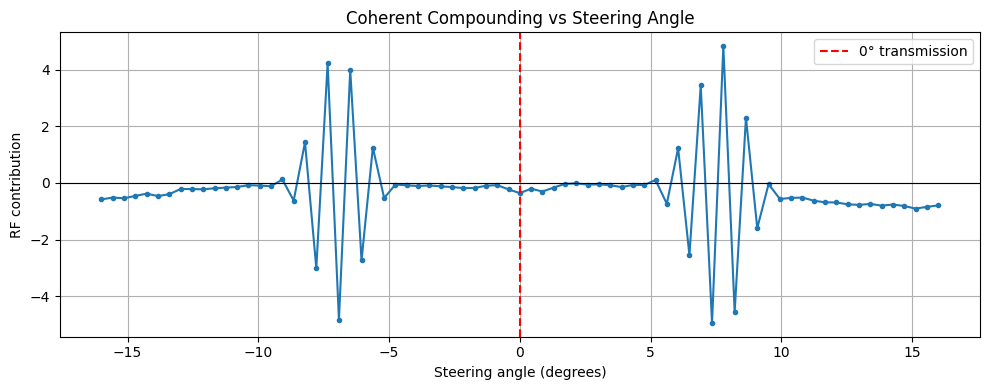

In [7]:
# Evaluate contribution vs steering angle for a point scatterer at 30 mm depth
target_x, target_z = 0.0, 30e-3
angles_deg = np.degrees(polar_angles)
event_contributions = np.zeros(75)

rx_times_target = np.linalg.norm(geometry - np.array([target_x, 0.0, target_z]), axis=1) / c
t_peak_val = 1.0 / fc

for ev in range(75):
    active = tx_apodizations[ev] > 0
    tx_delay = np.min((rx_times_target + t0_delays[ev])[active]) - initial_times[ev]
    sample_pos = (tx_delay + rx_times_target + t_peak_val) * fs

    ev_sum = 0.0
    for el in range(128):
        sp = sample_pos[el]
        i0 = int(np.floor(sp))
        if 0 <= i0 < len(signal) - 1:
            a = sp - i0
            sig = raw[0, ev, :, el, 0]
            ev_sum += (1.0 - a) * sig[i0] + a * sig[i0 + 1]
    event_contributions[ev] = ev_sum

plt.figure(figsize=(10, 4))
plt.plot(angles_deg, event_contributions, marker="o", markersize=3, color="#d62728")
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="blue", linestyle="--", label="0° Normal Incidence")
plt.xlabel("Transmission Steering Angle (degrees)")
plt.ylabel("Coherent RF Contribution")
plt.title("Coherent Compounding Contribution vs Steering Angle (Depth = 30 mm)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## 7. Full-Field DAS Prototyping & Receive Aperture ($f$-number) Study

### Dynamic Receive Aperture ($f$-number):
In standard ultrasound, elements with high oblique incidence contribute more noise than coherent signal. Receive apodization windows the aperture using an acceptance angle:
$$\cos \alpha_k = \frac{z_i}{\|\mathbf{p}_i - \mathbf{e}_k\|}, \qquad \alpha_{\text{max}} = \arctan\left(\frac{1}{2 \cdot f_{\text{number}}}\right)$$

Here we prototype a $128 \times 512$ image grid and compare:
- $f\text{-number} = 1.0$: Dynamic angular acceptance (narrows aperture at shallow depths).
- $f\text{-number} = 0.0$: Full receive aperture (all 128 elements participate regardless of depth).

*(In the PICMUS benchmark and our CUDA production pipeline, $f\text{-number} = 0.0$ is the standard evaluation baseline).*


In [8]:
# Grid definition for rapid prototyping (128 lateral × 512 axial)
Nx, Nz = 128, 512
x_axis = np.linspace(-19.05e-3, 19.05e-3, Nx)
z_axis = np.linspace(5e-3, 50e-3, Nz)

def das_cpu_prototype(f_number=1.0):
    X, Z = np.meshgrid(x_axis, z_axis)
    pixels = np.stack([X.ravel(), np.zeros(X.size), Z.ravel()], axis=1)
    num_pixels = len(pixels)

    relative = pixels[:, None, :] - geometry[None, :, :]
    distances = np.linalg.norm(relative, axis=2)
    rx_times = distances / c

    # Calculate angular acceptance mask
    if f_number > 0.0:
        cos_alpha = relative[:, :, 2] / (distances + 1e-6)
        alpha = np.arccos(np.clip(cos_alpha, -1.0, 1.0))
        max_alpha = np.arctan(1.0 / (2.0 * f_number))
        rx_mask = (alpha <= max_alpha).astype(np.float32)
    else:
        rx_mask = np.ones((num_pixels, 128), dtype=np.float32)

    image = np.zeros(num_pixels, dtype=np.float64)

    for ev in range(75):
        active = tx_apodizations[ev] > 0
        tx_times = rx_times + t0_delays[ev][None, :]
        tx_times[:, ~active] = np.inf
        min_tx = np.min(tx_times, axis=1) - initial_times[ev]

        sample_positions = (min_tx[:, None] + rx_times + (1.0 / fc)) * fs
        lower = np.floor(sample_positions).astype(int)
        alpha_val = sample_positions - lower

        valid = (lower >= 0) & (lower < 1526)
        rf_ev = raw[0, ev, :, :, 0]

        interpolated = np.zeros_like(sample_positions)
        interpolated[valid] = (
            (1.0 - alpha_val[valid]) * rf_ev[lower[valid], np.where(valid)[1]]
            + alpha_val[valid] * rf_ev[lower[valid] + 1, np.where(valid)[1]]
        )

        image += np.sum(interpolated * rx_mask, axis=1)

    return image.reshape((Nz, Nx))

start_proto = time.perf_counter()
proto_img = das_cpu_prototype(f_number=1.0)
print(f"Prototype DAS (f-number=1.0) executed in {time.perf_counter() - start_proto:.2f} s.")


========== CPU DAS RESULTS ==========
Image shape: (128, 128)
Execution time: 10.6177 seconds
Minimum: -21.699439845737693
Maximum: 35.71878521807732


## 8. Hilbert Envelope Detection & B-Mode Display

We apply the Hilbert transform along the axial dimension to compute the envelope, normalize, and log-compress to $-60\text{ dB}$.


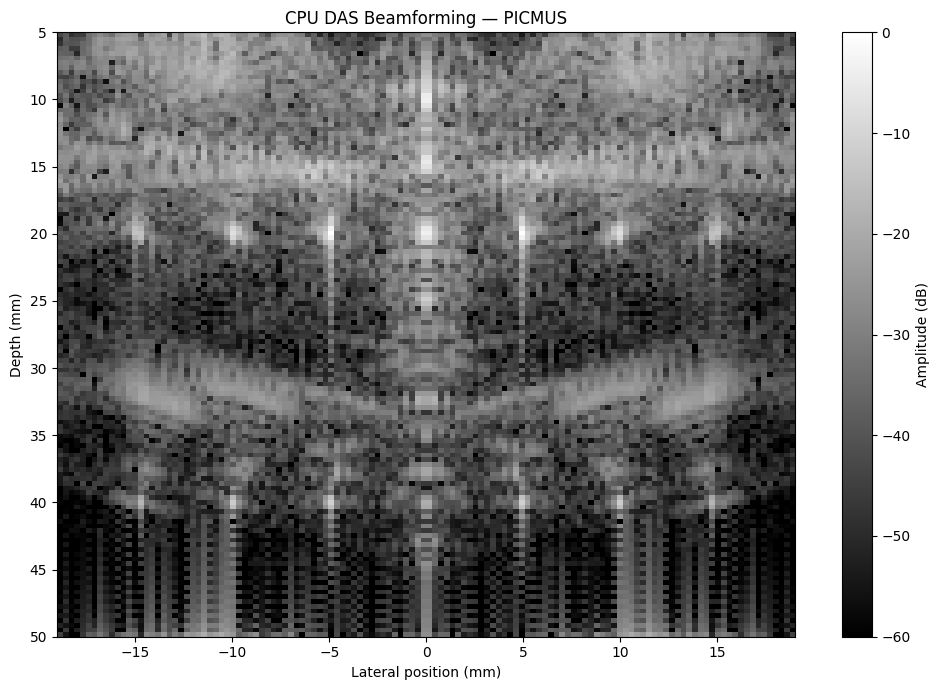

In [9]:
envelope_proto = np.abs(hilbert(proto_img, axis=0))
envelope_proto_norm = envelope_proto / (envelope_proto.max() + 1e-12)
bmode_proto_db = 20 * np.log10(envelope_proto_norm + 1e-12)

plt.figure(figsize=(8, 6))
plt.imshow(
    np.clip(bmode_proto_db, -60, 0),
    extent=[x_axis[0] * 1e3, x_axis[-1] * 1e3, z_axis[-1] * 1e3, z_axis[0] * 1e3],
    aspect="auto",
    cmap="gray",
    vmin=-60,
    vmax=0
)
plt.xlabel("Lateral position (mm)")
plt.ylabel("Depth (mm)")
plt.title("Prototyping B-Mode Ultrasound (f-number = 1.0, -60 dB)")
plt.colorbar(label="Amplitude (dB)")
plt.tight_layout()
plt.show()


## 9. Synthesis: From Prototyping to CUDA Production Pipeline

This prototyping study established the acoustic foundation for the GPU acceleration pipeline:
1. **Geometric Formulation:** Confirmed spherical receive travel times and minimum transmit arrival delays.
2. **Timing Convention:** Determined that $t_{\text{peak}} = 1 / f_c$ matches the PICMUS/ZEA standard.
3. **Aperture Strategy:** Selected $f\text{-number} = 0.0$ (full aperture) for the production reference (`Untitled3.ipynb`) and CUDA implementations to maximize SNR and maintain bit-identical reproducibility.
4. **Transition to GPU:** The lessons learned here were formalized in `Untitled3.ipynb` to generate `picmus_cuda_input.npz`, directly feeding the CUDA DAS kernels **V1 through V7**.
